# Lab 3.3: Metrics, Base Rates and Calibration

Run the cells from top to bottom. The output of the last cell is the validation section of your model card draft.

Data: Diabetes 130-US Hospitals (UCI, CC BY 4.0), the same file as Lab 3.2. Population: first encounter per patient, excluding death and hospice discharges, as in Strack et al. (2014).

In [1]:
import zipfile, urllib.request, tempfile
from pathlib import Path
import numpy as np, pandas as pd

UCI = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

def load_readmission():
    """Diabetes 130-US Hospitals (UCI, CC BY 4.0). Downloads once to a temporary folder;
    if you are offline, put diabetic_data.csv next to this notebook."""
    local = Path("diabetic_data.csv")
    if not local.exists():
        cache = Path(tempfile.gettempdir()) / "xai-ch03"
        cache.mkdir(exist_ok=True)
        local = cache / "diabetic_data.csv"
        if not local.exists():
            z = cache / "d.zip"
            urllib.request.urlretrieve(UCI, z)
            zipfile.ZipFile(z).extractall(cache)
    d = pd.read_csv(local)
    d["y"] = (d["readmitted"] == "<30").astype(int)          # target: back within 30 days
    d["age_n"] = d["age"].str.extract(r"\[(\d+)").astype(int)  # "[70-80)" -> 70
    for c in ["A1Cresult", "insulin", "change", "diabetesMed", "gender", "max_glu_serum"]:
        d[c + "_c"] = d[c].astype("category").cat.codes
    return d.sort_values("encounter_id").reset_index(drop=True)

NUM = ["age_n", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
       "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
CAT = ["admission_type_id", "discharge_disposition_id", "admission_source_id", "A1Cresult_c",
       "insulin_c", "change_c", "diabetesMed_c", "gender_c", "max_glu_serum_c"]
d = load_readmission()
print(d.shape)
pop = d[~d['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])].groupby('patient_nbr').head(1).reset_index(drop=True)
print('population:', len(pop), ' prevalence: %.3f' % pop['y'].mean())

(101766, 58)
population: 69990  prevalence: 0.090


## 1. Two models, one split

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

FEATS = NUM + CAT
tr, te = train_test_split(np.arange(len(pop)), test_size=0.3, random_state=0, stratify=pop['y'])
X, y = pop[FEATS], pop['y'].values
yte = y[te]
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0,
                                     categorical_features=[f in CAT for f in FEATS]).fit(X.iloc[tr], y[tr])
lr = make_pipeline(ColumnTransformer([('num', StandardScaler(), NUM),
                                      ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)]),
                   LogisticRegression(max_iter=2000)).fit(X.iloc[tr], y[tr])
P = {'boosted trees': gbm.predict_proba(X.iloc[te])[:, 1], 'logistic regression': lr.predict_proba(X.iloc[te])[:, 1]}
for k, p in P.items():
    print(f'{k:20s} AUC {roc_auc_score(yte, p):.3f}  average precision {average_precision_score(yte, p):.3f}  Brier {brier_score_loss(yte, p):.4f}')
print('prevalence (the average precision of a coin flip): %.3f' % yte.mean())

boosted trees        AUC 0.647  average precision 0.171  Brier 0.0792
logistic regression  AUC 0.643  average precision 0.157  Brier 0.0799
prevalence (the average precision of a coin flip): 0.090


**Checkpoint 1.** Both models reach an AUC of about 0.64 to 0.65 and an average precision of about 0.16 to 0.17, against a prevalence of about 0.09. Accuracy is missing on purpose: predicting "no readmission" for everyone would be about 91 percent accurate.

## 2. Thresholds turn scores into decisions

In [3]:
def at_threshold(p, t):
    flag = p >= t
    tp = (flag & (yte == 1)).sum(); fp = (flag & (yte == 0)).sum()
    fn = (~flag & (yte == 1)).sum(); tn = (~flag & (yte == 0)).sum()
    return dict(threshold=round(t, 3), flagged=int(flag.sum()), TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn),
                precision=round(tp / max(tp + fp, 1), 3), recall=round(tp / (tp + fn), 3))
p = P['boosted trees']
rows = [at_threshold(p, 0.5), at_threshold(p, np.quantile(p, 0.9)), at_threshold(p, np.quantile(p, 0.7))]
print(pd.DataFrame(rows).to_string(index=False))

 threshold  flagged  TP   FP   FN    TN  precision  recall
     0.500       25  13   12 1872 19100      0.520   0.007
     0.148     2100 428 1672 1457 17440      0.204   0.227
     0.095     6299 915 5384  970 13728      0.145   0.485


**Checkpoint 2.** At a threshold of 0.5 the model flags almost no one. Flagging the riskiest 10 percent catches roughly a fifth to a quarter of readmissions, and most flags are false alarms. That is what a precision of about 0.2 looks like to a nurse who has to call each flagged patient.

## 3. Calibration: does 20 percent mean 20 percent?

boosted trees mean predicted 0.090 vs observed 0.090
logistic regression mean predicted 0.090 vs observed 0.090


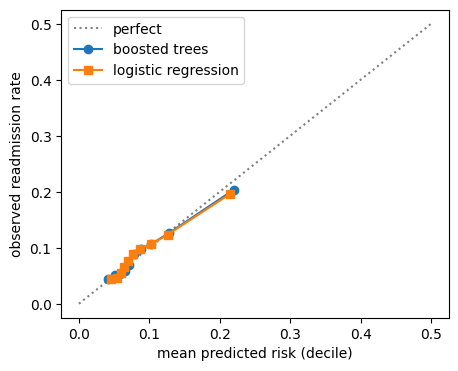

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot([0, 0.5], [0, 0.5], ':', color='gray', label='perfect')
for (k, p), mk in zip(P.items(), ['o', 's']):
    q = pd.qcut(p, 10, duplicates='drop')
    tab = pd.DataFrame({'p': p, 'y': yte}).groupby(q, observed=True).mean()
    ax.plot(tab['p'], tab['y'], marker=mk, label=k)
    print(k, 'mean predicted %.3f vs observed %.3f' % (p.mean(), yte.mean()))
ax.set_xlabel('mean predicted risk (decile)'); ax.set_ylabel('observed readmission rate'); ax.legend()
plt.show()

**Checkpoint 3.** On this split both curves should stay close to the diagonal within the range the models use (roughly 0.03 to 0.3). Calibration on the development population is the easy part; the hard part is a new hospital or a later year.

## 4. Simulate a new hospital with a different base rate

We keep only a random half of the readmitted patients in the test set, so the base rate falls, as it might at a hospital with better follow-up care. Ranking is untouched; calibration is not.

In [5]:
rng = np.random.default_rng(0)
keep = (yte == 0) | (rng.random(len(yte)) < 0.5)
p2, y2 = P['boosted trees'][keep], yte[keep]
print('new base rate %.3f, mean predicted %.3f' % (y2.mean(), p2.mean()))
print('AUC %.3f (before %.3f)' % (roc_auc_score(y2, p2), roc_auc_score(yte, P['boosted trees'])))
print('Brier %.4f' % brier_score_loss(y2, p2))

new base rate 0.048, mean predicted 0.089
AUC 0.649 (before 0.647)
Brier 0.0468


**Checkpoint 4.** The AUC barely moves, but the mean predicted risk (about 0.09) is now close to twice the observed rate (about 0.05). A clinician who reads the score as a real probability is misled, even though the ranking is as good as before.

## 5. Performance by group (a model card asks for this)

In [6]:
p = P['boosted trees']
age = pop['age_n'].values[te]
band = np.where(age < 50, 'under 50', np.where(age < 70, '50-69', '70 and over'))
rows = []
for b in ['under 50', '50-69', '70 and over']:
    m = band == b
    rows.append(dict(group=b, n=int(m.sum()), prevalence=round(yte[m].mean(), 3),
                     AUC=round(roc_auc_score(yte[m], p[m]), 3), mean_pred=round(p[m].mean(), 3)))
print(pd.DataFrame(rows).to_string(index=False))

      group    n  prevalence   AUC  mean_pred
   under 50 3447       0.076 0.636      0.069
      50-69 8412       0.081 0.660      0.084
70 and over 9138       0.103 0.625      0.104


## 6. The validation section of your model card draft

In [7]:
print(f'''## Validation (draft)\n- Data: Diabetes 130-US Hospitals 1999-2008 (UCI, CC BY 4.0); first encounter per patient, death and hospice discharges excluded; n = {len(pop)}.\n- Split: random 70/30 by patient (one encounter per patient, so rows = patients). No temporal or external test set: a known gap.\n- Target: readmission within 30 days; prevalence {yte.mean():.3f} in test.\n- Discrimination: AUC {roc_auc_score(yte, P['boosted trees']):.3f} (boosted trees), {roc_auc_score(yte, P['logistic regression']):.3f} (logistic regression).\n- Precision when flagging the top 10 percent: {at_threshold(P['boosted trees'], np.quantile(P['boosted trees'], 0.9))['precision']}; recall {at_threshold(P['boosted trees'], np.quantile(P['boosted trees'], 0.9))['recall']}.\n- Calibration: mean predicted {P['boosted trees'].mean():.3f} vs observed {yte.mean():.3f}; overstates risk about twofold if the base rate halves.\n- Leakage checks: aggregates computed from past encounters only; permutation importance reviewed (Lab 3.2).\n''')

## Validation (draft)
- Data: Diabetes 130-US Hospitals 1999-2008 (UCI, CC BY 4.0); first encounter per patient, death and hospice discharges excluded; n = 69990.
- Split: random 70/30 by patient (one encounter per patient, so rows = patients). No temporal or external test set: a known gap.
- Target: readmission within 30 days; prevalence 0.090 in test.
- Discrimination: AUC 0.647 (boosted trees), 0.643 (logistic regression).
- Precision when flagging the top 10 percent: 0.204; recall 0.227.
- Calibration: mean predicted 0.090 vs observed 0.090; overstates risk about twofold if the base rate halves.
- Leakage checks: aggregates computed from past encounters only; permutation importance reviewed (Lab 3.2).

